In [1]:
#Mount drive
from google.colab import drive
drive.mount('/content/gdrive')
DATA_PATH = '/content/gdrive/My Drive/'

Mounted at /content/gdrive


In [2]:
import numpy as np
from keras.layers import (Conv1D, MaxPooling1D, Dense, Dropout,
                          Flatten, Input, LayerNormalization,
                          MultiHeadAttention, GlobalAveragePooling1D,
                          GlobalMaxPooling1D, Add)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
import tensorflow as tf

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

from numpy import savetxt

# ──────────────────────────────────────────────────────────────────────────────
# 1. MOUNT GOOGLE DRIVE & LOAD DATA
# ──────────────────────────────────────────────────────────────────────────────



Xcu_train = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcu_train64x.npy')
Xcx_train = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcx_train64x.npy')
Xcy_train = np.load( '/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcy_train64x.npy')
Xcz_train = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcz_train64x.npy')

Xcu_test  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcu_test64x.npy')
Xcx_test  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcx_test64x.npy')
Xcy_test  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcy_test64x.npy')
Xcz_test  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcz_test64x.npy')

Yc_train  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Yc_train64x.npy')
Yc_test   = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Yc_val64x.npy')

Xcx_trainx = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcx_train15x.npy')
Xcy_trainx = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcy_train15x.npy')
Xcz_trainx = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcz_train15x.npy')

Xcx_testx  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcx_test15x.npy')
Xcy_testx  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcy_test15x.npy')
Xcz_testx  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xcz_test15x.npy')

Yc_trainx  = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Yc_train15x.npy')
Yc_testx   = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Yc_val15x.npy')

print("✅ Data loaded successfully!")
print(f"   Xcu_train shape : {Xcu_train.shape}")
print(f"   Xcx_train shape : {Xcx_train.shape}")
print(f"   Xcy_train shape : {Xcy_train.shape}")
print(f"   Xcz_train shape : {Xcz_train.shape}")
print(f"   Xcu_test  shape : {Xcu_test.shape}")
print(f"   Xcx_test  shape : {Xcx_test.shape}")
print(f"   Xcy_test  shape : {Xcy_test.shape}")
print(f"   Xcz_test  shape : {Xcz_test.shape}")
print(f"   Yc_train  shape : {Yc_train.shape}")
print(f"   Yc_train  shape : {Yc_train.shape}")

✅ Data loaded successfully!
   Xcu_train shape : (117000, 256, 1)
   Xcx_train shape : (117000, 256, 1)
   Xcy_train shape : (117000, 256, 1)
   Xcz_train shape : (117000, 256, 1)
   Xcu_test  shape : (13000, 256, 1)
   Xcx_test  shape : (13000, 256, 1)
   Xcy_test  shape : (13000, 256, 1)
   Xcz_test  shape : (13000, 256, 1)
   Yc_train  shape : (117000, 2)
   Yc_train  shape : (117000, 2)


In [3]:

# 1. PREPROCESSING FUNCTION
# ─────────────────────────────────────────────
# PREPROCESSING (4 SU → (N,256,4))
# ─────────────────────────────────────────────
def preprocess_4su(Xcu, Xcx, Xcy, Xcz, Y):

    Xcu = Xcu.squeeze(-1)
    Xcx = Xcx.squeeze(-1)
    Xcy = Xcy.squeeze(-1)
    Xcz = Xcz.squeeze(-1)

    X = np.stack([Xcu, Xcx, Xcy, Xcz], axis=-1)  # (N,256,4)

    return X.astype(np.float32), Y.astype(np.float32)

In [4]:
X_train, Y_train = preprocess_4su(Xcu_train, Xcx_train, Xcy_train, Xcz_train, Yc_train)
X_test,  Y_test  = preprocess_4su(Xcu_test,  Xcx_test,  Xcy_test,  Xcz_test,  Yc_test)

print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("Value range:", X_train.min(), X_train.max())
print("Label distribution:", np.sum(Y_train, axis=0))

X_train: (117000, 256, 4)
Y_train: (117000, 2)
Value range: 1.3652592e-06 158.52249
Label distribution: [58595. 58405.]


In [19]:
import tensorflow as tf

@tf.keras.utils.register_keras_serializable()
class PositionalEncoding(tf.keras.layers.Layer):

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def call(self, x):
        seq_len = tf.shape(x)[1]
        d_model = tf.shape(x)[2]

        pos = tf.cast(tf.range(seq_len), tf.float32)[:, tf.newaxis]
        i = tf.cast(tf.range(d_model), tf.float32)[tf.newaxis, :]

        angle_rates = 1.0 / tf.pow(
            10000.0,
            (2 * (i // 2)) / tf.cast(d_model, tf.float32)
        )

        angle_rads = pos * angle_rates

        sines = tf.sin(angle_rads[:, 0::2])
        cosines = tf.cos(angle_rads[:, 1::2])

        pos_encoding = tf.concat([sines, cosines], axis=-1)
        pos_encoding = pos_encoding[tf.newaxis, ...]

        return x + pos_encoding

    def get_config(self):
        config = super().get_config()
        return config



In [6]:

from tensorflow.keras.layers import BatchNormalization



#Transformer block
def transformer_block(x, d_model, num_heads, ff_dim, dropout=0.1):

    attn = tf.keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads
    )(x, x)

    attn = tf.keras.layers.Dropout(dropout)(attn)
    x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x + attn)

    ffn = tf.keras.layers.Dense(ff_dim, activation='relu')(x)
    ffn = tf.keras.layers.Dense(d_model)(ffn)

    ffn = tf.keras.layers.Dropout(dropout)(ffn)
    x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn)

    return x


#Transformer Model
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model

def build_cnn_transformer():

    inputs = Input(shape=(256, 4))   #  single input

    # ── CNN FEATURE EXTRACTION ───────────────────
    x = Conv1D(64, 3, padding='same', activation='relu')(inputs)
    x = BatchNormalization()(x)
    x = MaxPooling1D(2)(x)   # 256 → 128

    x = Conv1D(64, 3, padding='same', activation='relu')(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(2)(x)   # 128 → 64

    # ── POSITIONAL ENCODING ──────────────────────
    x = PositionalEncoding()(x)

    # ── TRANSFORMER ──────────────────────────────
    x = transformer_block(x, 64, num_heads=4, ff_dim=128)
    x = transformer_block(x, 64, num_heads=4, ff_dim=128)

    # ── GLOBAL POOL ──────────────────────────────
    x = GlobalAveragePooling1D()(x)

    # ── CLASSIFIER ───────────────────────────────
    x = Dense(64, activation='relu')(x)
    x = Dropout(0)(x)

    outputs = Dense(2, activation='softmax')(x)

    return Model(inputs, outputs)

# 6. BUILD & COMPILE
model = build_cnn_transformer()

model.compile(
    optimizer = Adam(learning_rate=1e-4),
    loss      = 'categorical_crossentropy',
    metrics   = ['accuracy']
)

model.summary()



Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 4)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 256, 64)   │        832 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 64)   │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 128, 64)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 128, 64)   │     12,352 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 64)   │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 64, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_encoding │ (None, 64, 64)    │          0 │ max_pooling1d_1[… │
│ (PositionalEncodin… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ positional_encod… │
│ (MultiHeadAttentio… │                   │            │ positional_encod… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64, 64)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64)    │          0 │ positional_encod… │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 64, 64)    │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64, 64)    │      8,256 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64, 64)    │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64, 64)    │          0 │ multi_head_atten

 Total params: 84,930 (331.76 KB)

 Trainable params: 84,674 (330.76 KB)

 Non-trainable params: 256 (1.00 KB)

In [8]:
model = build_cnn_transformer()

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train,
    Y_train,
    validation_data=(X_test, Y_test),
    epochs=50,
    batch_size=100,
    callbacks=[early_stop]
)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 4)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 256, 64)   │        832 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 64)   │        256 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 128, 64)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 128, 64)   │     12,352 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 64)   │        256 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 64, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_encodin… │ (None, 64, 64)    │          0 │ max_pooling1d_3[… │
│ (PositionalEncodin… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ positional_encod… │
│ (MultiHeadAttentio… │                   │            │ positional_encod… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 64, 64)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 64, 64)    │          0 │ positional_encod… │
│                     │                   │            │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 64, 64)    │      8,256 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 64, 64)    │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_5[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 64, 64)    │          0 │ multi_head_atten

 Total params: 84,930 (331.76 KB)

 Trainable params: 84,674 (330.76 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/50
1170/1170 ━━━━━━━━━━━━━━━━━━━━ 31s 11ms/step - accuracy: 0.8197 - loss: 0.3781 - val_accuracy: 0.8375 - val_loss: 0.3362
Epoch 2/50
1170/1170 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.8428 - loss: 0.3311 - val_accuracy: 0.8516 - val_loss: 0.3121
Epoch 3/50
1170/1170 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.8491 - loss: 0.3209 - val_accuracy: 0.8542 - val_loss: 0.3075
Epoch 4/50
1170/1170 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.8511 - loss: 0.3153 - val_accuracy: 0.8549 - val_loss: 0.3071
Epoch 5/50
1170/1170 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.8544 - loss: 0.3084 - val_accuracy: 0.8578 - val_loss: 0.3015
Epoch 6/50
1170/1170 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.8549 - loss: 0.3063 - val_accuracy: 0.8597 - val_loss: 0.2975
Epoch 7/50
1170/1170 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.8589 - loss: 0.3023 - val_accuracy: 0.8621 - val_loss: 0.2940
Epoch 8/50
1170/1170 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.8607 - loss

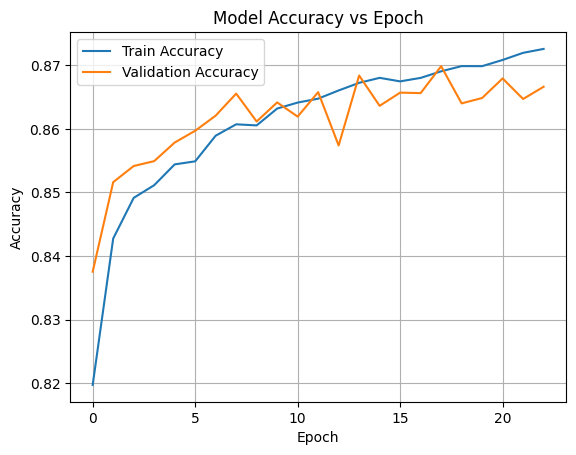

In [9]:
#plot accuracy vs Epoch
import matplotlib.pyplot as plt

# Accuracy plot
plt.figure()

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Model Accuracy vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train Accuracy', 'Validation Accuracy'])

plt.grid(True)
plt.show()

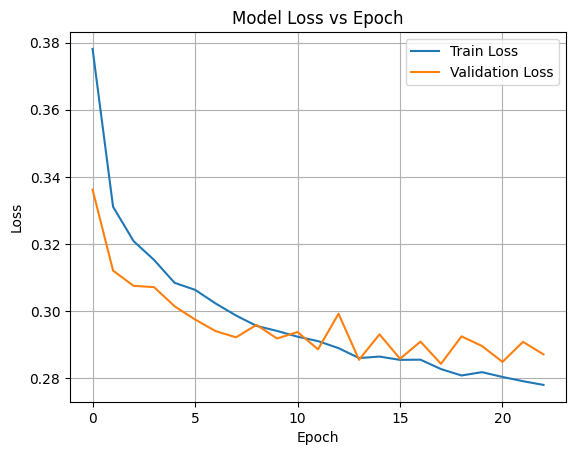

In [10]:
# Loss plot
plt.figure()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Model Loss vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train Loss', 'Validation Loss'])

plt.grid(True)
plt.show()

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from tensorflow.keras.models import load_model
import tensorflow as tf
from keras.models import load_model
from tensorflow.keras.layers import LSTM as OriginalLSTM


# Load Test Data
# ==============================
file_prefix = '/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Xc'
file_suffix = '_testX.npy'
file_suffix_p = '_testP.npy'

Xc = {}
Xcp = {}

for snr in range(10,21):
    Xc[f'Xc{snr}_testX'] = np.load(file_prefix + str(snr) + file_suffix)
    Xcp[f'Xc{snr}_testP'] = np.load(file_prefix + str(snr) + file_suffix_p)

print("Files loaded successfully ✅")

Yc_test = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Yc_testX.npy')
Yc_testP = np.load('/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/Yc_testP.npy')

Files loaded successfully ✅


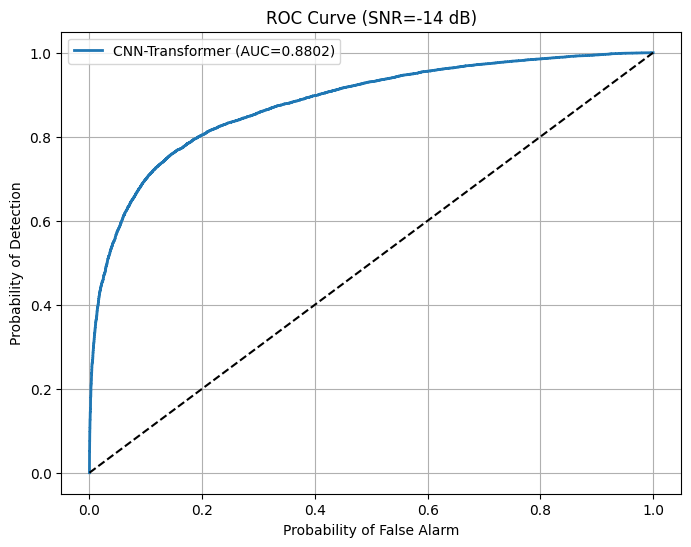

In [13]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

snr_value = 14

Xc14_test = Xc[f'Xc{snr_value}_testX']

S = 4
idx = np.arange(S+1) * int(Xc14_test.shape[0]/S)

Xu = Xc14_test[idx[0]:idx[1]]
Xx = Xc14_test[idx[1]:idx[2]]
Xy = Xc14_test[idx[2]:idx[3]]
Xz = Xc14_test[idx[3]:idx[4]]

Y14 = Yc_test[idx[0]:idx[4]]

# preprocessing
X14, Y14 = preprocess_4su(Xu, Xx, Xy, Xz, Y14)

# prediction
y_pred = model.predict(X14, verbose=0)

fp,tp,_ = roc_curve(Y14[:,1], y_pred[:,1])
roc_auc = auc(fp,tp)

plt.figure(figsize=(8,6))
plt.plot(fp,tp,lw=2,label=f'CNN-Transformer (AUC={roc_auc:.4f})')
plt.plot([0,1],[0,1],'k--')
plt.xlabel("Probability of False Alarm")
plt.ylabel("Probability of Detection")
plt.title("ROC Curve (SNR=-14 dB)")
plt.legend()
plt.grid(True)
plt.show()

<Figure size 600x600 with 0 Axes>

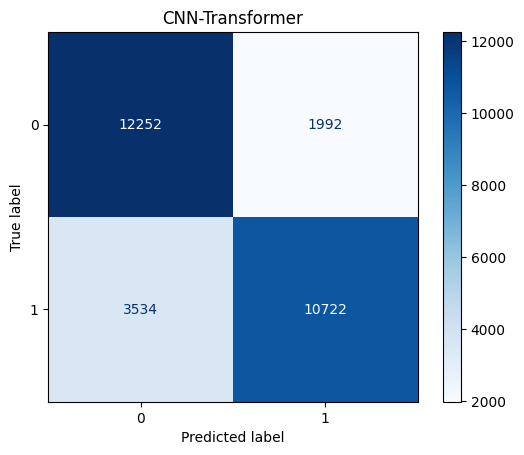

In [14]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

snr_value=14

X_test=Xc[f'Xc{snr_value}_testX']

idx=np.arange(5)*int(X_test.shape[0]/4)

Xu=X_test[idx[0]:idx[1]]
Xx=X_test[idx[1]:idx[2]]
Xy=X_test[idx[2]:idx[3]]
Xz=X_test[idx[3]:idx[4]]

Y_slice=Yc_test[idx[0]:idx[4]]

X_input,Y_input=preprocess_4su(Xu,Xx,Xy,Xz,Y_slice)

y=model.predict(X_input,verbose=0)

y_true=Y_input[:,1]

y_pred=(y[:,1]>=0.5).astype(int)

cm=confusion_matrix(y_true,y_pred)

plt.figure(figsize=(6,6))
ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.title("CNN-Transformer")
plt.show()

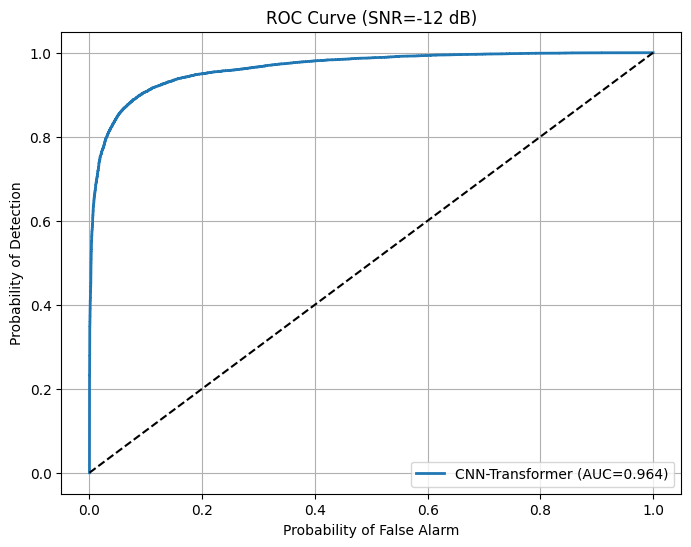

In [17]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

snr_value = 12

Xc12_test = Xc[f'Xc{snr_value}_testX']

S = 4
idx = np.arange(S+1) * int(Xc12_test.shape[0]/S)

Xu = Xc12_test[idx[0]:idx[1]]
Xx = Xc12_test[idx[1]:idx[2]]
Xy = Xc12_test[idx[2]:idx[3]]
Xz = Xc12_test[idx[3]:idx[4]]

Y12 = Yc_test[idx[0]:idx[4]]

# preprocessing
X12, Y12 = preprocess_4su(Xu, Xx, Xy, Xz, Y14)

# prediction
y_pred = model.predict(X12, verbose=0)

fp,tp,_ = roc_curve(Y12[:,1], y_pred[:,1])
roc_auc = auc(fp,tp)

plt.figure(figsize=(8,6))
plt.plot(fp,tp,lw=2,label=f'CNN-Transformer (AUC={roc_auc:.3f})')
plt.plot([0,1],[0,1],'k--')
plt.xlabel("Probability of False Alarm")
plt.ylabel("Probability of Detection")
plt.title("ROC Curve (SNR=-12 dB)")
plt.legend()
plt.grid(True)
plt.show()



In [20]:
# Save the trained CNN-Transformer model

model.save("/content/gdrive/MyDrive/Cognitive Radio Dataset/IEEE SIMO Dataset/CNN-Transformer2.keras")


print("Model saved successfully!")

Model saved successfully!
